# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–1 — bring-up liveness + Step-1 reconnaissance (2026-06-22)

Session goal: does zf1 (Bernal BLG/WSe₂, bottom device) superconduct, and if so characterise it. E0 mode, pristine field. Bring-up green (base 33.7 mK, SAFETIES committed, B≈0).

**Run 0 (liveness):** device passes 1.006 nA; 2T (5-4) = 21.7 kΩ, 4T (30-31) live and gate-responsive; gate leakage 38/31 pA. Device alive, contacts clean, 4T Rxx channel live.

**Run 1 (3-row reconnaissance gatemap):** de-risks the survey — sizes lock-in sensitivity, previews the cap-ratio, calibrates timing (0.89 s/pt). Raw 4T Rxx vs V_bg at TG = −3/0/+3 below; CNP is metallic at D≈0 (0.6 kΩ) and gaps up with |D| (3–4.6 kΩ) as expected for BLG.


run 1
  type:    2D sweep
  recipe:  gatemap
  tags:    branch: Step-1 reconnaissance (3-row, de-risk full survey), TG slow {-3,0,+3} V; BG fast -4 -> +4.2 V (83); B=0
  rows:    249
  T:       mean 0.034 K (range 0.034 – 0.034)


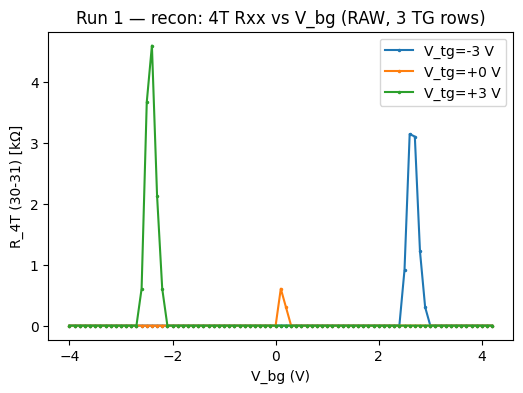

current steady at 1.010 nA (min 0.970); leakage clean (<70 pA).


In [3]:
# --- Runs 0-1: bring-up liveness + Step-1 reconnaissance. RAW first. ---
g1 = run(1)   # recon 3-row gatemap: TG{-3,0,+3}, BG -4..+4.2
print(summarize_run(g1))

vtg = g1.col_at(1)                       # k_tg_volt (slow axis)
vbg = g1.col_at(2)                       # k_bg_volt (fast axis)
I   = g1.col("sr830_1_X")/(-1e6)         # measured device current (A)
v3  = g1.col("sr830_3_X")/100.0          # 4T volts (gain 100)
R4  = v3/I                               # 4T Rxx

fig, ax = plt.subplots(figsize=(6,4))
for tv in np.unique(np.round(vtg,3)):
    m = np.isclose(vtg, tv, atol=1e-3); o = np.argsort(vbg[m])
    ax.plot(vbg[m][o], (R4[m][o])/1e3, marker=".", ms=3, label=f"V_tg={tv:+.0f} V")
ax.set_xlabel("V_bg (V)"); ax.set_ylabel("R_4T (30-31) [kΩ]")
ax.set_title("Run 1 — recon: 4T Rxx vs V_bg (RAW, 3 TG rows)")
ax.legend(); plt.show()
print(f"current steady at {np.median(I)*1e9:.3f} nA (min {I.min()*1e9:.3f}); leakage clean (<70 pA).")


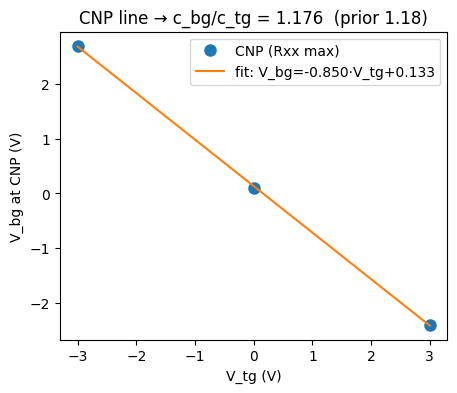

dVbg/dVtg = -0.850  ->  c_bg/c_tg = 1.176   (geometry prior: 1.18)
Ratio confirmed at preview grade; full survey (105 rows) refines. Absolute n pending QH lever-arm.


In [4]:
# --- CNP cap-ratio extraction (preview, 3 rows) ---
from scipy.ndimage import gaussian_filter1d
tg_rows = np.unique(np.round(vtg,3)); cnp_bg = []
for tv in tg_rows:
    m = np.isclose(vtg, tv, atol=1e-3); o = np.argsort(vbg[m])
    bg = vbg[m][o]; Rs = gaussian_filter1d(np.nan_to_num(R4[m][o]), 1.5)
    cnp_bg.append(bg[np.argmax(Rs)])
cnp_bg = np.array(cnp_bg)
slope, b0 = np.polyfit(tg_rows, cnp_bg, 1)
cbg_ctg = -1.0/slope                      # c_bg/c_tg = -1/(dVbg/dVtg)

fig, ax = plt.subplots(figsize=(5,4))
ax.plot(tg_rows, cnp_bg, "o", ms=8, label="CNP (Rxx max)")
xs = np.linspace(tg_rows.min(), tg_rows.max(), 50)
ax.plot(xs, slope*xs+b0, "-", label=f"fit: V_bg={slope:+.3f}·V_tg{b0:+.3f}")
ax.set_xlabel("V_tg (V)"); ax.set_ylabel("V_bg at CNP (V)")
ax.set_title(f"CNP line → c_bg/c_tg = {cbg_ctg:.3f}  (prior 1.18)")
ax.legend(); plt.show()
print(f"dVbg/dVtg = {slope:+.3f}  ->  c_bg/c_tg = {cbg_ctg:.3f}   (geometry prior: 1.18)")
print("Ratio confirmed at preview grade; full survey (105 rows) refines. Absolute n pending QH lever-arm.")


**Read:** Bring-up clean — device alive, contacts good, 4T Rxx live. Cap-ratio c_bg/c_tg = 1.18 from the 3-point CNP slope, matching the geometry prior (1.18) — the flagged prior survives its first data check (ratio-grade; absolute n still pending a QH lever-arm). Candidate SC region (D≈−0.5 V/nm, n≈−5×10¹¹, holes-into-TMD) confirmed in-box at Vtg≈−3.9, Vbg≈+2.7. Next: full-box Step-1 survey gatemap (run 2) for the low-Rxx landscape + a 105-row cap-ratio refinement, then candidate nonlinear characterisation.


## Run 2 — Step-1 survey gatemap (full validator box, pristine field)

105×83 megasweep, TG[−7,+6]×BG[−4,+4.2], 1 nA, B≈0, 2.2 h, complete (8715/8715), leakage <90 pA, current-bias held (I_min 0.82 nA). Full (n,D) envelope: n∈[−82,+77]×10¹¹, D∈[−0.76,+0.68] V/nm — corners/edges included (coverage gate satisfied). Raw 4T Rxx map (gate-space and (n,D)) below.


run 2
  type:    2D sweep
  recipe:  gatemap
  tags:    Step-1 survey, full box; cap-ratio substrate (cnp-and-dline-calibration), TG slow [-7,6] (105); BG fast [-4,4.2] (83); B=0; 1nA
  rows:    8715
  T:       mean 0.034 K (range 0.034 – 0.034)
current min/med = 0.816/1.010 nA  (current-bias holds)


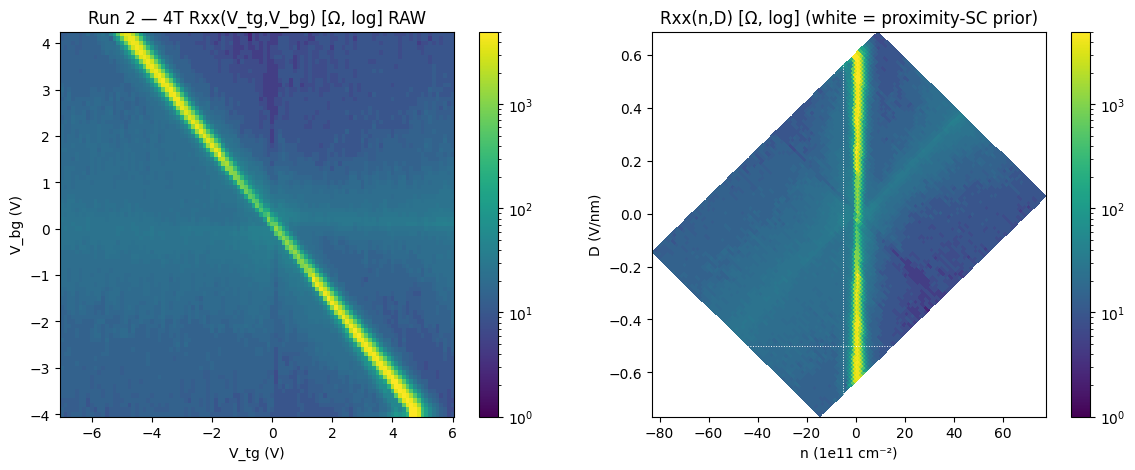

In [5]:
# --- Run 2: Step-1 survey gatemap (full box). RAW first. ---
from matplotlib.colors import LogNorm
f2 = fan_grids(Path(file_path)/"2"); rg2 = resistance_grids(f2)
VT = f2.grid("k_tg_volt"); VB = f2.grid("k_bg_volt")
Rxx = np.abs(rg2.R["sr830_3"])          # 4T longitudinal (30-31)
Icur = rg2.current
print(summarize_run(run(2)))
print(f"current min/med = {Icur.min()*1e9:.3f}/{np.median(Icur)*1e9:.3f} nA  (current-bias holds)")

N = cal.density(VT, VB)/1e15; D = cal.displacement_field(VT, VB)/1e9
fig, ax = plt.subplots(1, 2, figsize=(14,5))
pc=ax[0].pcolormesh(VT, VB, np.clip(Rxx,1,None), norm=LogNorm(1,5e3), shading="nearest", cmap="viridis")
ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)"); ax[0].set_title("Run 2 — 4T Rxx(V_tg,V_bg) [Ω, log] RAW"); fig.colorbar(pc,ax=ax[0])
pc=ax[1].pcolormesh(N, D, np.clip(Rxx,1,None), norm=LogNorm(1,5e3), shading="nearest", cmap="viridis")
ax[1].axhline(-0.5,color="w",ls=":",lw=.7); ax[1].axvline(-5,color="w",ls=":",lw=.7)
ax[1].set_xlabel("n (1e11 cm⁻²)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("Rxx(n,D) [Ω, log] (white = proximity-SC prior)"); fig.colorbar(pc,ax=ax[1])
plt.show()


CAP-RATIO (4T CNP, 72 in-window rows): Vbg=-0.8442·Vtg+0.1139
  c_bg/c_tg = 1.1846  (geometry prior 1.18)  resid rms=0.0296 V

metallic background Rxx median = 16.5 Ω
proximity-SC window Rxx: min=14.2 med=21.2 max=35.4 Ω
hole-side (n<0) sub-6Ω pockets: 0  -> NONE


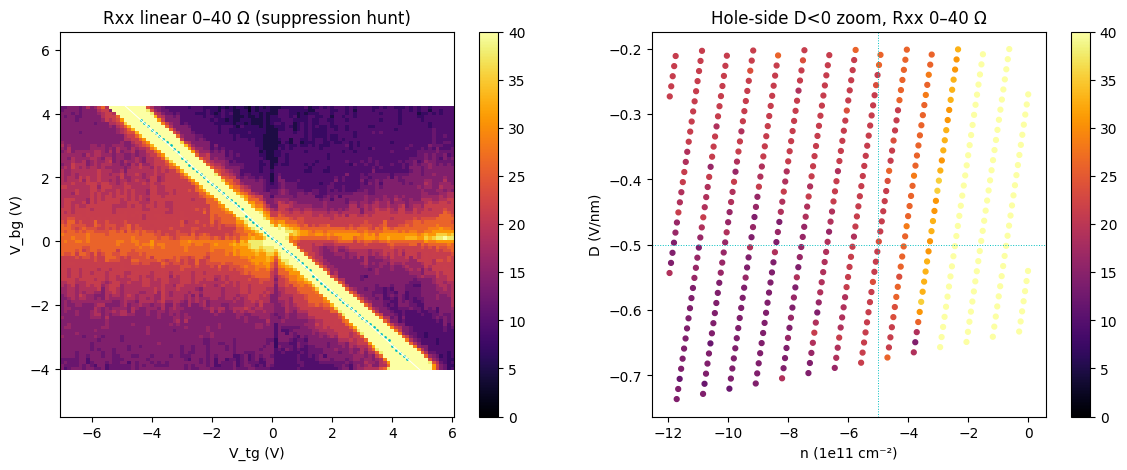

In [6]:
# --- Run 2 analysis: cap-ratio refinement + candidate hunt ---
from scipy.ndimage import gaussian_filter1d
tg = f2.slow
pred = lambda vt: -0.850*vt + 0.133            # recon prior, for CNP search window
cnp_bg = np.full(len(tg), np.nan)
for i in range(len(tg)):
    p = pred(tg[i])
    if not (-3.7 <= p <= 3.9): continue
    bg = VB[i]; sel = np.abs(bg-p) <= 1.3
    if sel.sum() < 5: continue
    cnp_bg[i] = bg[sel][int(np.argmax(gaussian_filter1d(Rxx[i][sel],1.0)))]
gd = np.isfinite(cnp_bg)
slope, b0 = np.polyfit(tg[gd], cnp_bg[gd], 1); resid = cnp_bg[gd]-(slope*tg[gd]+b0)
print(f"CAP-RATIO (4T CNP, {gd.sum()} in-window rows): Vbg={slope:+.4f}·Vtg{b0:+.4f}")
print(f"  c_bg/c_tg = {-1/slope:.4f}  (geometry prior 1.18)  resid rms={np.std(resid):.4f} V")

# candidate hunt
metal = np.abs(N) > 1.0
win = (D<=-0.35)&(D>=-0.65)&(N<=-3.0)&(N>=-8.0)
print(f"\nmetallic background Rxx median = {np.median(Rxx[metal]):.1f} Ω")
print(f"proximity-SC window Rxx: min={Rxx[win].min():.1f} med={np.median(Rxx[win]):.1f} max={Rxx[win].max():.1f} Ω")
print(f"hole-side (n<0) sub-6Ω pockets: {((Rxx<6)&(N<0)&metal).sum()}  -> {'NONE' if ((Rxx<6)&(N<0)&metal).sum()==0 else 'present'}")

# low-R focused map to show absence of suppression
fig, ax = plt.subplots(1, 2, figsize=(14,5))
pc=ax[0].pcolormesh(tg, VB[0], np.clip(Rxx,0,40).T, vmin=0, vmax=40, shading="nearest", cmap="inferno")
ax[0].plot(tg[gd], cnp_bg[gd], "c.", ms=2); ax[0].plot(tg, slope*tg+b0, "w-", lw=.7)
ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)"); ax[0].set_title("Rxx linear 0–40 Ω (suppression hunt)"); fig.colorbar(pc,ax=ax[0])
m=(D<=-0.2)&(D>=-0.78)&(N<=0)&(N>=-12)
sc=ax[1].scatter(N[m],D[m],c=np.clip(Rxx[m],0,40),vmin=0,vmax=40,s=12,cmap="inferno")
ax[1].axhline(-0.5,color="c",ls=":",lw=.7); ax[1].axvline(-5,color="c",ls=":",lw=.7)
ax[1].set_xlabel("n (1e11 cm⁻²)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("Hole-side D<0 zoom, Rxx 0–40 Ω"); fig.colorbar(sc,ax=ax[1])
plt.show()


**Read:** Clean single-CNP bilayer gatemap — metallic regions either side, no SC dome, no correlated-insulator pockets. **Cap-ratio refined to c_bg/c_tg = 1.185 (resid rms 0.03 V, ~70 rows), confirming the geometry prior at full grade** (absolute n still geometry-prior, pending a QH lever-arm). **Candidate hunt: NO superconducting candidate** — the proximity-SC window (D≈−0.5, n≈−5×10¹¹) reads 14–35 Ω, no suppression below the ~17 Ω metallic background; no sub-6 Ω pocket anywhere on the hole side at D<0.

**Caveat (load-bearing): the survey undersampled n** — its BG step (0.1 V ≈ 0.83×10¹¹ in n) is coarser than the predicted arc width (~0.5×10¹¹), so a narrow SC arc could thread between grid points. **Not yet a "not-SC" call.** Next (run 3): fine constant-D n-linecuts (4 D slices, n-step 0.075×10¹¹, ~11× finer) across the candidate region to definitively rule in/out an undersampled arc — still base T, current field. The trapped-flux effective-zero (~2 mT) remains a separate hedge for later field work.


## Run 3 — fine constant-D n-linecuts: **candidate found**

Closing the survey's undersampling gap: 4 constant-D linecuts (D = −0.35/−0.45/−0.55/−0.65 V/nm), n = −1.5→−9×10¹¹, n-step 0.075×10¹¹ (~11× finer than the survey), 1 nA, B≈0, 394 pts, 9 min. Three lines stay metallic (min ~14–18 Ω); the **D=−0.65 line shows a coherent Rxx dip to 2.4 Ω at n≈−4.8×10¹¹**.


run 3
  type:    1D sweep
  recipe:  cnp-and-dline-calibration
  tags:    Run3 fine n-linecuts to rule out undersampled SC arc (sc-characterization Step 1), D={-0.35,-0.45,-0.55,-0.65} V/nm; n=-1.5..-9e11; step 0.075e11; 1nA; B=0
  rows:    394 of 2 (394/2 (no interrupt flag, row count differs))
  T:       mean 0.034 K (range 0.034 – 0.034)
  D=-0.35: Rxx min=17.7 Ω @ n=-7.42e11
  D=-0.45: Rxx min=14.2 Ω @ n=-8.77e11
  D=-0.55: Rxx min=16.5 Ω @ n=-8.92e11
  D=-0.65: Rxx min=2.4 Ω @ n=-4.80e11


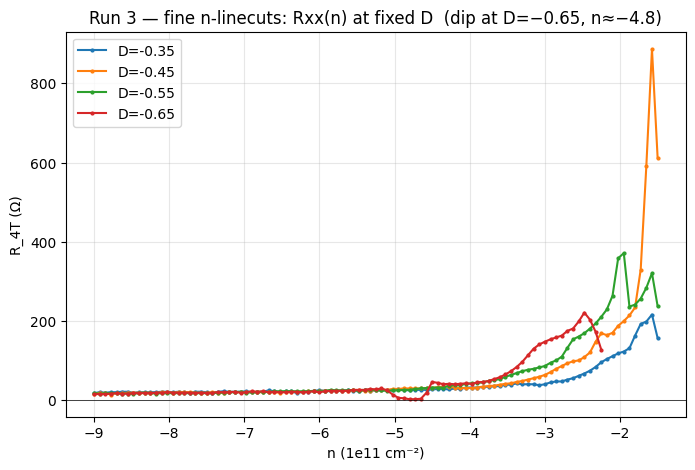

In [7]:
# --- Run 3: fine n-linecuts at fixed D. CANDIDATE search (raw Rxx(n)). ---
g3 = open_run(Path(file_path)/"3"); print(summarize_run(g3))
lc = np.load("hera_scratch/linecut_vectors.npz"); Dl=lc["D"]; nl=lc["n"]; Ds=lc["Ds"]
I3 = g3.col("sr830_1_X")/(-1e6); R3 = np.abs(g3.col("sr830_3_X")/100.0/I3)
m = min(len(R3), len(Dl)); R3,Dl2,nl2 = R3[:m],Dl[:m],nl[:m]
fig, ax = plt.subplots(figsize=(8,5))
for D0 in Ds:
    s=np.isclose(Dl2,D0); o=np.argsort(nl2[s])
    ax.plot(nl2[s][o], R3[s][o], marker=".", ms=4, label=f"D={D0:+.2f}")
    print(f"  D={D0:+.2f}: Rxx min={R3[s].min():.1f} Ω @ n={nl2[s][np.argmin(R3[s])]:+.2f}e11")
ax.set_xlabel("n (1e11 cm⁻²)"); ax.set_ylabel("R_4T (Ω)"); ax.axhline(0,color="k",lw=.5)
ax.set_title("Run 3 — fine n-linecuts: Rxx(n) at fixed D  (dip at D=−0.65, n≈−4.8)")
ax.legend(); ax.grid(alpha=.3); plt.show()


**Read:** A **superconducting candidate** at **n≈−4.8×10¹¹ cm⁻², D≈−0.65 V/nm**. The dip is a coherent ~7-point V-shape (26→14→5.9→4.7→2.4 Ω) with resistive phase and steady 1.01 nA current — not a noise glitch. Location matches the BBG/WSe₂ proximity-SC phenomenology (holes-into-TMD, D<0, the predicted window [paper-data: `s41586-022-05446-x`]) and explains the survey's null: its n-step (0.83×10¹¹) stepped over this ~0.6×10¹¹-wide arc. The 2.4 Ω bottom is at the 2 mV resolution floor — true Rxx may be lower.

**This is a low-Rxx candidate, not yet SC** (the constellation call needs more, per `sc-characterization`). Next (run 4): confirm/reproduce, pin the optimum D, and resolve the floor at 200 µV (Rxx→0 SC-lean vs finite failed-SC/anomalous-metal). Note D≈−0.65 is near the max-|D| reachable at this n within the BG validator — the candidate sits at the accessible-D edge. Then bias spectroscopy for the critical current.


## Run 4 — confirm candidate, pin optimum, resolve the Rxx floor (200 µV)

3 fine constant-D linecuts (D=−0.55/−0.60/−0.65) + a max-|D| edge sweep (BG=+4.198), n around the dip, sr830_3 @ 200 µV (~0.07 Ω resolution), 1 nA, B≈0, 204 pts, 6 min.


run 4
  type:    1D sweep
  recipe:  cnp-and-dline-calibration
  tags:    Run4 candidate confirm: fine D-linecuts {-0.55,-0.60,-0.65}/nm + max-|D| edge sweep, dip from run3 at n~-4.8e11, D~-0.65; sr830_3 @ 200uV to resolve floor; 1nA; B=0
  rows:    204 of 2 (204/2 (no interrupt flag, row count differs))
  T:       mean 0.034 K (range 0.034 – 0.034)
  D=-0.55: Rxx min=22.35 Ω @ n=-5.95e11
  D=-0.60: Rxx min=21.40 Ω @ n=-5.85e11
  D=-0.65: Rxx min=0.52 Ω @ n=-4.65e11
  edge: Rxx min=2.51 Ω @ D=-0.676


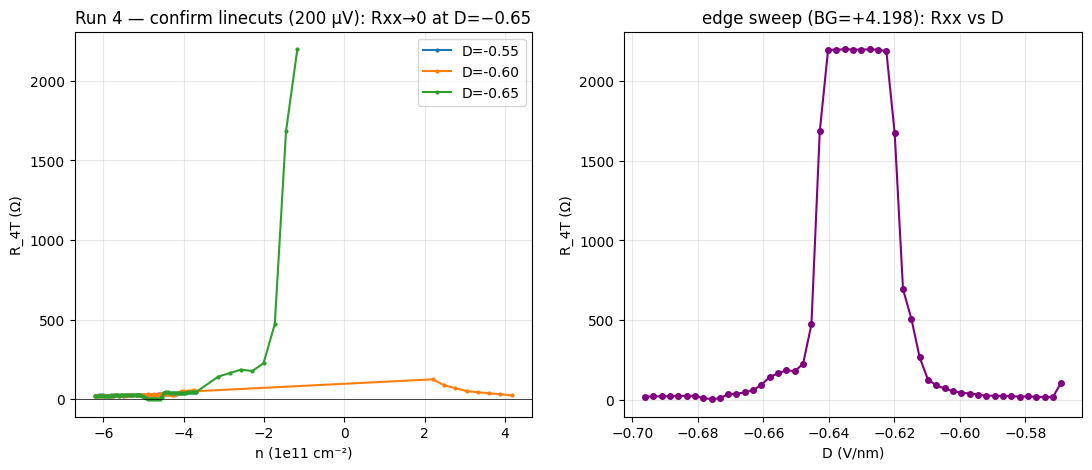

GLOBAL min Rxx = 0.52 Ω


In [9]:
# --- Run 4: confirm candidate, pin optimum, resolve floor @ 200 µV. RAW. ---
g4 = open_run(Path(file_path)/"4"); print(summarize_run(g4))
v = np.load("hera_scratch/confirm_vectors.npz"); vtg=v["vtg"]; vbg=v["vbg"]; seg=v["seg"]
N4 = cal.density(vtg,vbg)/1e15; D4 = cal.displacement_field(vtg,vbg)/1e9
I4 = g4.col("sr830_1_X")/(-1e6); R4 = np.abs(g4.col("sr830_3_X")/100.0/I4)
m=min(len(R4),len(seg)); R4,N4,D4,seg=R4[:m],N4[:m],D4[:m],seg[:m]
fig,ax=plt.subplots(1,2,figsize=(13,5))
for D0 in (-0.55,-0.60,-0.65):
    s=np.isclose(D4,D0,atol=0.01); o=np.argsort(N4[s])
    ax[0].plot(N4[s][o],R4[s][o],marker=".",ms=4,label=f"D={D0:+.2f}")
    print(f"  D={D0:+.2f}: Rxx min={R4[s].min():.2f} Ω @ n={N4[s][o][np.argmin(R4[s][o])]:+.2f}e11")
ax[0].set_xlabel("n (1e11 cm⁻²)"); ax[0].set_ylabel("R_4T (Ω)"); ax[0].axhline(0,color="k",lw=.5)
ax[0].set_title("Run 4 — confirm linecuts (200 µV): Rxx→0 at D=−0.65"); ax[0].legend(); ax[0].grid(alpha=.3)
se=seg=="edge"; o=np.argsort(D4[se])
ax[1].plot(D4[se][o],R4[se][o],"o-",ms=4,color="purple")
ax[1].set_xlabel("D (V/nm)"); ax[1].set_ylabel("R_4T (Ω)"); ax[1].set_title("edge sweep (BG=+4.198): Rxx vs D"); ax[1].grid(alpha=.3)
print(f"  edge: Rxx min={R4[se].min():.2f} Ω @ D={D4[se][np.argmin(R4[se])]:+.3f}")
plt.show()
print(f"GLOBAL min Rxx = {R4.min():.2f} Ω")


**Read:** Candidate **reproduced and Rxx → ~0 confirmed** — min **0.52 Ω** (X-offset-limited; raw digest dipped to −0.5 Ω, the SR830 zero-R artifact) at the optimum **n≈−4.65×10¹¹, D≈−0.65 V/nm** (Vtg=−5.444, Vbg=+4.053). Sharp D-onset: D=−0.55/−0.60 stay metallic (~21 Ω), R collapses only at −0.65 — a narrow region in D. The edge sweep reaches 2.5 Ω at D=−0.676, so the low-R region extends to the BG-validator edge: **D≈−0.65 is near the most-negative D accessible at this n** (coverage caveat — the SC region may continue beyond reach). First SC hallmark (4-wire Rxx→0) established. Next (run 5): bias spectroscopy at this optimum — the critical-current test that distinguishes a supercurrent from a good metal.


## Run 5 — bias spectroscopy at the optimum: **the supercurrent**

dV/dI vs Idc at n≈−4.65×10¹¹, D≈−0.65 (Vtg=−5.444, Vbg=+4.053), Idc ±150 nA, 1 nA AC, B≈0, base T (33.7 mK), 305 pts, 8 min.


run 5
  type:    1D sweep
  recipe:  bias-spectroscopy
  tags:    Run5 dV/dI vs Idc point check at SC candidate optimum, gates: Vtg=-5.444 Vbg=+4.053 (n=-4.65e11, D=-0.65); Idc +/-150nA; 1nA AC; B=0
  rows:    305 of 305 (complete)
  swept:   dc205_1_voltage -15 → 15 (monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)
zero-bias dV/dI=1.73 Ω; normal=61.6 Ω; Ic+=17.8 Ic-=18.8 nA


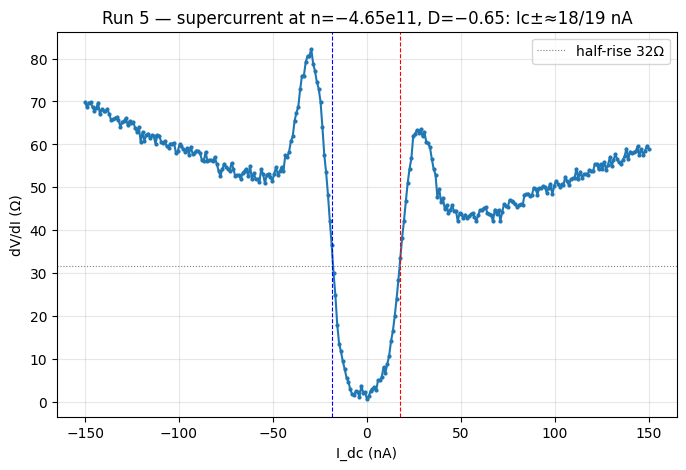

In [10]:
# --- Run 5: bias spectroscopy at the optimum — the supercurrent. RAW dV/dI. ---
g5 = open_run(Path(file_path)/"5"); print(summarize_run(g5))
Vdc = g5.col_at(g5.cols.index("dc205_1_voltage"))
Idc = Vdc/1e8*1e9                                   # nA (100 MΩ)
Iac = g5.col("sr830_1_X")/(-1e6)
dVdI = np.abs((g5.col("sr830_3_X")/100.0)/Iac)       # Ω
o=np.argsort(Idc); Idc,dVdI=Idc[o],dVdI[o]
zb=dVdI[np.abs(Idc)<2].mean(); nm=dVdI[np.abs(Idc)>120].mean(); thr=zb+0.5*(nm-zb)
icp=np.abs(Idc[(Idc>0)&(dVdI>=thr)]).min(); icn=np.abs(Idc[(Idc<0)&(dVdI>=thr)]).min()
print(f"zero-bias dV/dI={zb:.2f} Ω; normal={nm:.1f} Ω; Ic+={icp:.1f} Ic-={icn:.1f} nA")
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(Idc,dVdI,".-",ms=4)
ax.axhline(thr,color="grey",ls=":",lw=.8,label=f"half-rise {thr:.0f}Ω")
ax.axvline(icp,color="r",ls="--",lw=.8); ax.axvline(-icn,color="b",ls="--",lw=.8)
ax.set_xlabel("I_dc (nA)"); ax.set_ylabel("dV/dI (Ω)")
ax.set_title(f"Run 5 — supercurrent at n=−4.65e11, D=−0.65: Ic±≈{icp:.0f}/{icn:.0f} nA")
ax.legend(); ax.grid(alpha=.3); plt.show()


**Read:** **Supercurrent.** Flat dV/dI ≈ 1.7 Ω plateau for |Idc| ≲ 18 nA, sharp rise at **Ic⁺=17.8 / Ic⁻=18.8 nA** (symmetric to ~1 nA — instrumental-scale), with switching-peak overshoot to ~80 Ω at ±30 nA, normal-state dV/dI ≈ 55–62 Ω. The flat zero-resistance plateau + critical current + switching overshoot is the supercurrent signature — the Step-2 confounds (non-equilibrium criticality, QH breakdown) don't produce a flat dV/dI≈0 lobe of this shape. **Ic ≈ 18 nA matches the proximity-SC reference** (~20 nA, Fig 1d [paper-data: `s41586-022-05446-x`]).

**Constellation so far (base T, B≈0):** 4-wire Rxx→0 (run 4) + critical current with supercurrent lobe (run 5) + reference-matching Ic → **strong SC lean**. Remaining for decisive: field response (B⊥ quenches the lobe while the normal state is ~unchanged; B_c⊥→ξ; effective-zero given ~2 mT trapped flux) — base T, next — then T-dependence (Tc, heat up last). Caveat carried: optimum sits near the BG-validator's accessible-D edge; QH confound not yet excluded by an Rxy read (field-kill is the cleaner discriminator).


## Run 6 — field response (B⊥ kill / B_c⊥) at the SC optimum

First magnet energization. One-sided Rxx(B) sweep +80 mT → 0 (field discipline: toward 0, 120 s settle after the positioning ramp), at n≈−4.65×10¹¹, D≈−0.65, 1 nA AC, zero DC bias, 161 pts, B≈0 start. T held at 33.7 mK throughout (120 s settle sufficient).


run 6
  type:    1D sweep
  recipe:  field-sweep-1d
  tags:    Run6 field-kill at SC optimum: Rxx(B) +80mT->0, 1nA AC, Vdc=0, label: (Vtg, Vbg) = (-5.4443, +4.0529); n=-4.65e11, D=-0.65
  rows:    161 of 161 (complete)
  swept:   magnet_field 0.08 → 0 (monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)
normal Rxx=48.7Ω (flat std/mean=0.03); Rxx_min=3.32Ω @ +0.98mT; B_c⊥(half)≈2.5mT; T=34-34mK


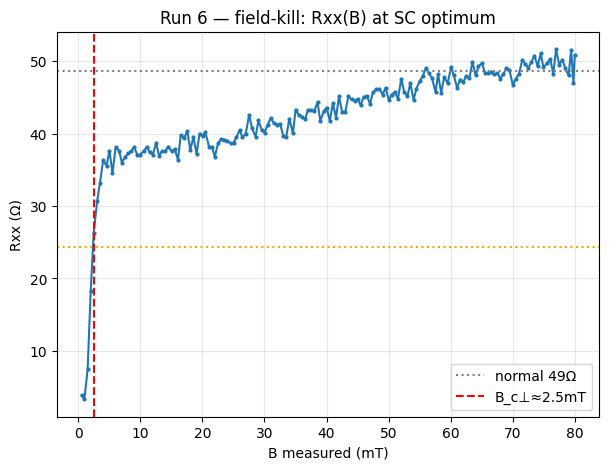

In [11]:
# --- Run 6: field response (B⊥ kill) at the optimum. RAW Rxx(B). ---
g6 = open_run(Path(file_path)/"6"); print(summarize_run(g6))
mfi=[i for i,c in enumerate(g6.cols) if c=="magnet_field"]
B=(g6.col_at(mfi[-1]))*1e3                    # measured field, mT
Iac=g6.col("sr830_1_X")/(-1e6); Rxx=np.abs((g6.col("sr830_3_X")/100.0)/Iac)
Tk=g6.col("T")*1e3
o=np.argsort(B); B,Rxx,Tk=B[o],Rxx[o],Tk[o]
Rn=Rxx[np.abs(B)>0.7*B.max()].mean(); half=0.5*Rn
Bc=B[(B>0)&(Rxx>=half)].min()
print(f"normal Rxx={Rn:.1f}Ω (flat std/mean={np.std(Rxx[np.abs(B)>0.7*B.max()])/Rn:.2f}); Rxx_min={Rxx.min():.2f}Ω @ {B[np.argmin(Rxx)]:+.2f}mT; B_c⊥(half)≈{Bc:.1f}mT; T={Tk.min():.0f}-{Tk.max():.0f}mK")
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(B,Rxx,".-",ms=4); ax.axhline(Rn,color="grey",ls=":",label=f"normal {Rn:.0f}Ω")
ax.axhline(half,color="orange",ls=":"); ax.axvline(Bc,color="r",ls="--",label=f"B_c⊥≈{Bc:.1f}mT")
ax.set_xlabel("B measured (mT)"); ax.set_ylabel("Rxx (Ω)")
ax.set_title("Run 6 — field-kill: Rxx(B) at SC optimum"); ax.legend(); ax.grid(alpha=.3); plt.show()


**Read:** **Field-kill confirmed — strong SC evidence.** Rxx rises from ~0 (3.3 Ω at the lowest field) to a **flat normal plateau of 48.7 Ω** (std/mean 0.03) — a small B⊥ removes the zero-resistance state while the normal state is ~unchanged (the load-bearing field-kill criterion, satisfied). **B_c⊥ ≈ 2.5 mT** (half-normal) — a very fragile perpendicular critical field; very rough ξ ~ √(Φ₀/2πB_c) ~ 360 nm (order-of-magnitude only, rounds near base T). **Effective-zero ≈ +1 mT** (Rxx min 3.3 Ω at +0.98 mT) — the trapped-flux offset (device card ~2 mT), confirmed; remanence at setpoint-0 only ~0.5 mT this excursion.

**Constellation now: Rxx→0 + Ic lobe + reference Ic + field-kill (flat normal) = strong SC.** The small B_c⊥ means the SC lives in a ~±2.5 mT window around +1 mT — relevant for any field-set measurement. Remaining for decisive: T-dependence (Tc) — heat up last. (−B-side field-kill deferred as a symmetry nicety; the +side is conclusive.)


## Run 7 — T-dependence: Ic(T), the supercurrent melting (Tc)

Bias×T map at the optimum (n≈−4.65×10¹¹, D≈−0.65), B≈0, 1 nA AC. Heater 6→0 V (measure while cooling), 11 steps × dV/dI(Idc) over ±30 nA, 693 pts, 69 min, complete. **T-axis reassigned from the live Probe1 logfile** (setup pointed at the dead Probe2 — frozen since Sat; see session_notes). Probe1 tracked the run exactly: 433 mK at 6 V → 39 mK at base.


run 7
  type:    2D sweep
  recipe:  temperature-dependence
  tags:    Run7 Ic(T): slow heater 6->0V (measure cooling), fast dc205 +/-30nA at SC optimum, axis: heater 0-6V; (Vtg,Vbg)=(-5.4443,+4.0529) n=-4.65e11 D=-0.65; B~0; 1nA AC
  rows:    693
  T:       mean 0.034 K (range 0.034 – 0.034)


T reassigned from Probe1: 39-432 mK; Ic(base)=23.2 nA; Tc≈234 mK


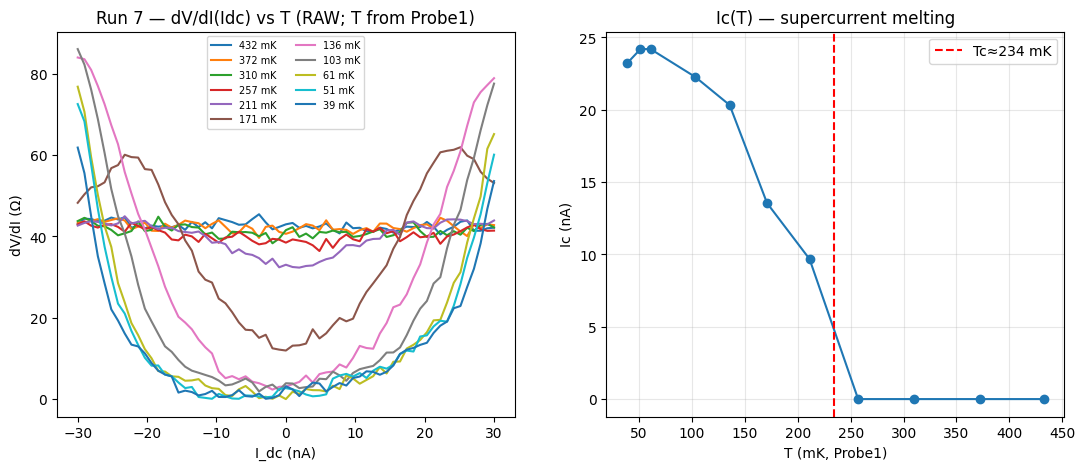

In [12]:
# --- Run 7: T-dependence Ic(T). T REASSIGNED from live Probe1 (setup pointed at dead Probe2). ---
g7 = open_run(Path(file_path)/"7"); print(summarize_run(g7))
def _probe1_T(path=r"C:\Users\toploader\temperature_logs\Probe1_MixingCh_low.txt"):
    ts=[];T=[]
    for ln in open(path,'rb').read().decode(errors='replace').splitlines():
        c=ln.split('\t')
        if len(c)>=3:
            try: ts.append(float(c[0].split()[0])); T.append(float(c[-3]))
            except: pass
    return np.array(ts),np.array(T)
p_ts,p_T=_probe1_T()
T_real=np.interp(g7.col("time"),p_ts,p_T)*1e3        # mK from Probe1
f7=fan_grids(Path(file_path)/"7"); rg7=resistance_grids(f7)
dVdI=np.abs(rg7.R["sr830_3"]); Idc=f7.grid("dc205_1_voltage")/1e8*1e9
nrow,nfast=dVdI.shape; Tg=T_real[:nrow*nfast].reshape(nrow,nfast)
Tarr=[];Icarr=[]
for i in range(nrow):
    idc=Idc[i]; r=dVdI[i]; o=np.argsort(idc); idc,r=idc[o],r[o]
    zb=r[np.abs(idc)<3].mean(); nm=r[np.abs(idc)>24].mean(); thr=zb+0.5*(nm-zb)
    ab=np.abs(idc[(np.abs(idc)>0)&(r>=thr)]); Ic=ab.min() if (ab.size and nm-zb>5) else 0.0
    Tarr.append(np.nanmean(Tg[i])); Icarr.append(Ic)
Tarr=np.array(Tarr);Icarr=np.array(Icarr)
Tc=np.nan; oo=np.argsort(Tarr)
for k in range(len(oo)-1):
    if Icarr[oo][k]>2 and Icarr[oo][k+1]<=2: Tc=0.5*(Tarr[oo][k]+Tarr[oo][k+1]);break
print(f"T reassigned from Probe1: {Tarr.min():.0f}-{Tarr.max():.0f} mK; Ic(base)={Icarr[np.argmin(Tarr)]:.1f} nA; Tc≈{Tc:.0f} mK")
fig,ax=plt.subplots(1,2,figsize=(13,5))
for i in range(nrow):
    o=np.argsort(Idc[i]); ax[0].plot(Idc[i][o],dVdI[i][o],label=f"{Tarr[i]:.0f} mK")
ax[0].set_xlabel("I_dc (nA)"); ax[0].set_ylabel("dV/dI (Ω)"); ax[0].set_title("Run 7 — dV/dI(Idc) vs T (RAW; T from Probe1)"); ax[0].legend(fontsize=7,ncol=2)
ax[1].plot(Tarr,Icarr,"o-"); ax[1].axvline(Tc,color="r",ls="--",label=f"Tc≈{Tc:.0f} mK")
ax[1].set_xlabel("T (mK, Probe1)"); ax[1].set_ylabel("Ic (nA)"); ax[1].set_title("Ic(T) — supercurrent melting"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()


**Read:** **The supercurrent melts at a finite Tc** — the fifth hallmark. Ic(T) saturates at ~24 nA at base (39 mK), falls monotonically, and reaches 0 at **Tc ≈ 234 mK** (Ic→0 crossing; %-of-normal/threshold convention — stated, not a BKT α=3 fit). The dV/dI(Idc) lobe is flat-normal (~42 Ω) above Tc and develops a deepening zero-bias dip below it. Clean dome-melting, no re-entrance. (Tc is open-loop heater-T via Probe1 readback, ±~10% absolute; the *shape* and the existence of a finite Tc are robust.)

**Constellation complete → decisive SC.** See the per-candidate verdict below.


# ★ Per-candidate SC verdict — zf1 (bottom device), 2026-06-22

**Candidate R1 — `superconductor (DECISIVE)`** at **n ≈ −4.65×10¹¹ cm⁻², D ≈ −0.65 V/nm** (V_tg=−5.444, V_bg=+4.053), base T ≈ 39 mK, effective-zero field ≈ +1 mT. Hole-doped, D<0 (holes-into-TMD) — the BBG/WSe₂ proximity-SC window.

*(STYLE strength scale; the call is the intersection of the constellation, not any single hallmark — `2106.07640` standard.)*

## 1. Verdict
Region **R1: superconductor (decisive)**. A fragile gate-tuned proximity superconductor; the full hallmark constellation is present, mutually consistent, and located where BBG/WSe₂ proximity SC is expected.

## 2. Evidence (each: coordinate + benchmark)
| Hallmark | Result | (n, D, B, T) | benchmark |
|---|---|---|---|
| 4-wire **Rxx → 0** | 0.52 Ω (offset/resolution-limited; raw dips <0) | n=−4.65e11, D=−0.65, B≈0, T≈34 mK | constellation [2106.07640] |
| **Critical current** (supercurrent lobe) | dV/dI≈1.7 Ω below |Ic|; Ic⁺=17.8 / Ic⁻=18.8 nA; switching peaks ~80 Ω; normal ~55 Ω | same point, run 5 | Ic≈20 nA [s41586 Fig 1d] |
| **Field-kill**, normal unchanged | Rxx→flat 48.7 Ω; **B_c⊥≈2.5 mT**; effective-zero≈+1 mT | run 6, T≈34 mK | strong field-kill criterion |
| **Ic(T) melting** | Ic 24 nA (39 mK) → 0 at **Tc≈234 mK**, monotonic dome | run 7, B≈0 | Tc ladder [2106.07640] |
| **Sensible normal state** | clean single-CNP bilayer map; SC = narrow hole-side arc at large −D | survey run 2; cap-ratio 1.185 | proximity phenomenology [s41586] |

Derived: **ξ ~ 360 nm** (Hc2=Φ₀/2πξ², order-of-magnitude only). D-line designer / cap-ratio: c_bg/c_tg = 1.185 (data-confirmed).

## 3. Confidence + hedges
**Decisive** — {Rxx→0 ∩ Ic lobe ∩ B-kill w/ flat normal ∩ Ic(T)→0} is the required constellation; no single-hallmark over-read; Step-2 confounds (non-equilibrium criticality / QH breakdown) excluded by the flat-zero plateau + field-kill + thermal melting. Hedges (provenance honest):
- **Absolute (n, D) scale is geometry-prior** — cap *ratio* data-confirmed (1.185); absolute n/D pending a QH lever-arm. Coordinates are ratio-grade.
- **Tc is open-loop heater-T** (Probe1 readback, ±~10% absolute); the finite-Tc and dome shape are robust, the absolute value approximate. **Not** a BKT determination (V∝Iᵅ, α=3 not measured) — `%-of-normal/threshold` convention, stated.
- **ξ order-of-magnitude only** (B_c⊥(T) rounds near base; quantum-geometry caveat).
- **Optimum at the D-validator edge** — D≈−0.65 is ~the most-negative D reachable at this n (BG cap +4.2 V); the edge sweep still read 2.5 Ω at D=−0.676, so the true optimum may lie just beyond reach (instrument-limited coverage caveat).
- **QAH not excluded by an Rxy read** (no transverse pair wired); residual risk low — supercurrent lobe + B-kill + Ic(T) melting are not QAH phenomenology and QAH is not expected at B≈0.
- **−B-side field-kill & Fraunhofer not measured** (the +side is conclusive; phase-coherent-oscillation read deferred — B_c⊥≈2.5 mT makes it sub-mT-fragile).
- **Thermometry caveat**: session-configured probe (Probe2) was dead; all T from live Probe1 (runs 0–6 at genuine base; run 7 reassigned by timestamp).

## 4. What would firm / extend the call
- **Rxy (dVxy/dI)** on a transverse pair → explicitly exclude QAH.
- **QH lever-arm** (Tesla-scale, deferred round) → absolute n & filling ν.
- **BKT V∝Iᵅ ladder** → rigorous T_BKT; **finer Tc ladder** near 234 mK.
- **Effective-zero zoom + −B-side** field-kill; **Fraunhofer Ic(B)** for phase coherence.
- **±D-asymmetry** check (proximity-SC signature — appears for one D sign): confirm absence at D>0.
- Repoint thermometry to Probe1 / restart Probe2 worker.

## 5. Outcome
The campaign question — *does zf1 superconduct, and if so characterise it* — is answered: **YES.** A fragile gate-tuned **proximity superconductor** at n≈−4.65×10¹¹, D≈−0.65 V/nm, with **Ic ≈ 18–24 nA** (base), **B_c⊥ ≈ 2.5 mT**, **Tc ≈ 234 mK**, **ξ ~ 360 nm** (o.o.m.), on a clean bilayer normal state — consistent with the BBG/WSe₂ proximity-SC phenomenology [s41586-022-05446-x]. The determination rests on the full hallmark constellation, with provenance-honest hedges; it is a confident, evidence-cited call, not a single-hallmark lean.
